![Python Banner](../../Image/05_04_doubleML.png)


# 4.7 Cluster Robust Double Machine Learning

When rows are clustered — students in classrooms, products in markets, years of the same firm — errors inside a cluster move together. Two pieces of DML have to change.

1. **Sample splitting.** A random row split puts two rows from the same cluster on opposite sides of a fold, so the nuisance model memorizes the cluster. Assign folds by cluster id.
2. **Standard errors.** Sum the orthogonal scores inside each cluster, then take the variance of those totals (Cameron, Gelbach, and Miller, 2011; Chiang, Kato, Ma, and Sasaki, 2021). Two-way clustering adds the two one-way variances and subtracts the intersection.

An interval that ignores the clusters is too narrow.


## Overview

The score is the partially linear IV moment. After cross-fitting,

$$\hat\theta = \frac{\sum_i \tilde Z_i \tilde Y_i}{\sum_i \tilde Z_i \tilde D_i}, \qquad
\psi_i = \frac{\tilde Z_i(\tilde Y_i - \hat\theta \tilde D_i)}{\overline{\tilde Z\tilde D}}.$$

The cluster-robust standard error replaces $\psi_i$ with $\Psi_c = \sum_{i \in c} \psi_i$. The asymptotics need many clusters, not just many rows. A working rule is 30 or more clusters in each dimension you cluster on.

| Design | Correlation | Variance |
|--------|-------------|----------|
| One-way | Rows that share one id | Variance of that id's score totals |
| Two-way | Rows that share either of two ids | Sum of the two one-way variances, minus the cell variance |


## Implementation in Python

Part 1 simulates a two-way grid in the spirit of Chiang et al. (2021). Part 2 turns the second shock off. Part 3 uses `Data/BLP.csv` (Berry, Levinsohn, and Pakes): demand residual `y`, log price as the treatment, an instrument built from other firms' `hpwt` in the same market, and clusters `model.id` and `cdid`.

Nuisances are cross-fitted lasso fits. Folds are assignments of cluster ids.


## Set Up


In [1]:
import subprocess
import sys
from pathlib import Path

def _repo_root() -> Path:
    here = Path.cwd().resolve()
    for cand in [here, *here.parents]:
        if (cand / "pyproject.toml").is_file() and (cand / "src" / "pycausalml").is_dir():
            return cand
    raise FileNotFoundError(
        "PyCausalML repository was not found. Run this notebook from the repository."
    )

root = _repo_root()
data_dir = root / "Data"
if not data_dir.is_dir():
    raise FileNotFoundError(
        "The Data directory was not found. It should sit next to pyproject.toml."
    )

try:
    import pycausalml  # noqa: F401
    print("PyCausalML ready.")
except ImportError:
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "-q", "-e", f"{root}[plot]"],
    )
    print("PyCausalML installed.")
print("Data directory:", data_dir)


PyCausalML ready.
Data directory: /home/zia207/Github/PyCausalML/Data


In [2]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.ensemble import (
    GradientBoostingClassifier,
    GradientBoostingRegressor,
    RandomForestClassifier,
    RandomForestRegressor,
)
from sklearn.linear_model import Lasso, LassoCV, LogisticRegression, Ridge
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    brier_score_loss,
    mean_squared_error,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

from pycausalml import (
    CausalForestDML,
    InteractiveRegressionDML,
    KernelDML,
    LinearDML,
    NonParamDML,
    PartiallyLinearDML,
    SparseLinearDML,
    explain_cate,
)
from pycausalml.interpretation import plot_cate_hist

plt.rcParams["figure.dpi"] = 110
print("Imported PyCausalML")


Imported PyCausalML


In [3]:
def fold_ids(labels, n_folds, seed):
    labels = np.asarray(labels)
    uniq = np.unique(labels)
    rng = np.random.default_rng(seed)
    order = rng.permutation(uniq)
    mapping = {label: i % n_folds for i, label in enumerate(order)}
    return np.array([mapping[label] for label in labels])


def cross_fit_lasso(X, y, folds, alpha=0.05):
    pred = np.zeros(len(y), dtype=float)
    y = np.asarray(y, dtype=float)
    for fold in np.unique(folds):
        te = folds == fold
        tr = ~te
        if tr.sum() < 10 or te.sum() == 0:
            pred[te] = np.mean(y[tr]) if tr.any() else np.mean(y)
            continue
        scaler = StandardScaler()
        Xtr = scaler.fit_transform(X[tr])
        model = Lasso(alpha=alpha, max_iter=8000)
        model.fit(Xtr, y[tr])
        pred[te] = model.predict(scaler.transform(X[te]))
    return pred


def cluster_variance(psi, clusters):
    totals = pd.DataFrame({"psi": psi, "c": clusters}).groupby("c")["psi"].sum().to_numpy()
    g = len(totals)
    return (g / (g - 1.0)) * np.sum(totals ** 2) / (len(psi) ** 2)


def twoway_se(psi, cluster_i, cluster_j):
    pair = pd.Series(np.asarray(cluster_i).astype(str)) + ":" + pd.Series(np.asarray(cluster_j).astype(str))
    variance = cluster_variance(psi, cluster_i) + cluster_variance(psi, cluster_j) - cluster_variance(psi, pair.to_numpy())
    return float(np.sqrt(max(variance, 0.0)))


def pliv(X, y, d, z, folds, alpha=0.05):
    y_res = y - cross_fit_lasso(X, y, folds, alpha)
    d_res = d - cross_fit_lasso(X, d, folds, alpha)
    z_res = z - cross_fit_lasso(X, z, folds, alpha)
    denom = float(np.mean(z_res * d_res))
    theta = float(np.dot(z_res, y_res) / np.dot(z_res, d_res))
    psi = z_res * (y_res - theta * d_res) / denom
    iid_se = float(np.std(psi, ddof=1) / np.sqrt(len(psi)))
    return theta, psi, iid_se


def make_cluster_pliv(n_i=20, n_j=20, p=25, theta=1.0, seed=0, one_way=False):
    rng = np.random.default_rng(seed)
    ii, jj = np.meshgrid(np.arange(n_i), np.arange(n_j), indexing="ij")
    cluster_i, cluster_j = ii.ravel(), jj.ravel()
    n = len(cluster_i)
    shock_i = rng.normal(size=n_i)
    shock_j = np.zeros(n_j) if one_way else rng.normal(size=n_j)
    X = rng.normal(scale=0.4, size=(n, p))
    X[:, 0] += shock_i[cluster_i] + shock_j[cluster_j]
    eps = rng.normal(size=n) + 0.8 * (shock_i[cluster_i] + shock_j[cluster_j])
    instrument = 0.8 * X[:, 1] + rng.normal(size=n)
    treatment = 0.7 * instrument + 0.3 * X[:, 2] + 0.5 * eps + rng.normal(scale=0.3, size=n)
    outcome = theta * treatment + 0.8 * X[:, 0] + eps
    return X, outcome, treatment, instrument, cluster_i, cluster_j


print("Cluster helpers ready")


Cluster helpers ready


## Part 1: Two-way clusters

A $20 \times 20$ grid. The true effect is 1. Most covariates are noise, so the nuisance is a lasso. Each cluster dimension is split into 3 folds; the product is 9 folds.


In [4]:
X, y, d, z, ci, cj = make_cluster_pliv(seed=7)
folds = fold_ids(ci, 3, 1) * 3 + fold_ids(cj, 3, 2)
theta, psi, iid_se = pliv(X, y, d, z, folds, alpha=0.08)
print("Folds", len(np.unique(folds)))
print("Estimate", round(theta, 3), "(true value 1)")
print("i.i.d. SE", round(iid_se, 3))
print("Two-way SE", round(twoway_se(psi, ci, cj), 3))


Folds 9
Estimate 1.052 (true value 1)
i.i.d. SE 0.07
Two-way SE 0.048


## Part 2: One-way clusters

The second shock is off. Folds follow only the first cluster id, so there are $K$ folds rather than $K^2$.


In [5]:
X1, y1, d1, z1, ci1, _cj1 = make_cluster_pliv(seed=8, one_way=True)
folds1 = fold_ids(ci1, 3, 3)
theta1, psi1, iid1 = pliv(X1, y1, d1, z1, folds1, alpha=0.08)
print("Estimate", round(theta1, 3))
print("i.i.d. SE", round(iid1, 3), "| one-way SE", round(float(np.sqrt(cluster_variance(psi1, ci1))), 3))


Estimate 0.933
i.i.d. SE 0.08 | one-way SE 0.075


## Part 3: Automobile demand (BLP)

`Data/BLP.csv`. Outcome `y`, treatment log price (price shifted by 11.761 before the log), instrument equal to the sum of `hpwt` over other firms in the same market. Covariates `hpwt`, `air`, `mpd`, and `space` are expanded to squares and interactions.


In [6]:
blp = pd.read_csv(data_dir / "BLP.csv")
blp["log_price"] = np.log(blp["price"] + 11.761)
poly = PolynomialFeatures(degree=2, include_bias=False)
X_blp = poly.fit_transform(blp[["hpwt", "air", "mpd", "space"]].to_numpy(dtype=float))
market_sum = blp.groupby("cdid")["hpwt"].transform("sum")
firm_sum = blp.groupby(["cdid", "firm.id"])["hpwt"].transform("sum")
instrument = (market_sum - firm_sum).to_numpy(dtype=float)
y_blp = blp["y"].to_numpy(dtype=float)
d_blp = blp["log_price"].to_numpy(dtype=float)
product = blp["model.id"].to_numpy()
market = blp["cdid"].to_numpy()
print(blp.shape, "markets", blp["cdid"].nunique(), "models", pd.Series(product).nunique())


(2217, 17) markets 20 models 557


In [7]:
specs = {
    "No clustering": (fold_ids(np.arange(len(blp)), 4, 4), "iid"),
    "Product": (fold_ids(product, 4, 5), "product"),
    "Market": (fold_ids(market, 4, 6), "market"),
    "Product and market": (fold_ids(product, 2, 7) * 2 + fold_ids(market, 2, 8), "two"),
}
rows = []
for name, (folds_b, kind) in specs.items():
    theta_b, psi_b, iid_b = pliv(X_blp, y_blp, d_blp, instrument, folds_b, alpha=0.02)
    if kind == "iid":
        se = iid_b
    elif kind == "product":
        se = float(np.sqrt(cluster_variance(psi_b, product)))
    elif kind == "market":
        se = float(np.sqrt(cluster_variance(psi_b, market)))
    else:
        se = twoway_se(psi_b, product, market)
    rows.append({"Specification": name, "Estimate": theta_b, "Std. err": se, "Folds": int(len(np.unique(folds_b)))})
blp_table = pd.DataFrame(rows)
blp_table.round(4)


,Specification,Estimate,Std. err,Folds
0,No clustering,-7.6243,0.6523,4
1,Product,-7.5528,1.0393,4
2,Market,-6.7954,0.7563,4
3,Product and market,-7.2918,1.1787,4


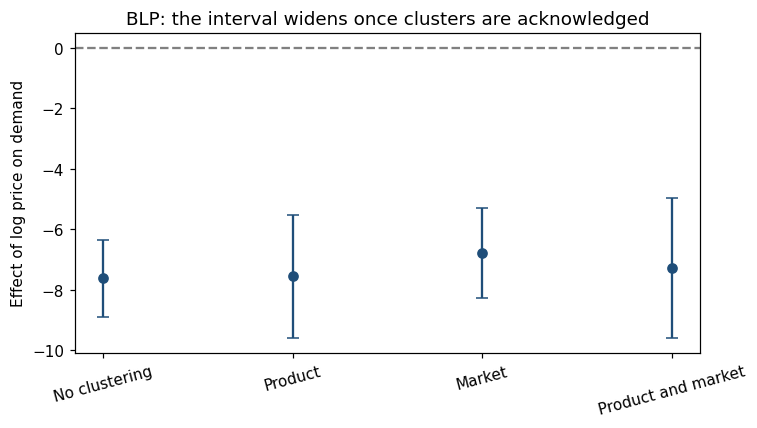

In [8]:
fig, ax = plt.subplots(figsize=(7.0, 4.0))
ax.errorbar(np.arange(len(blp_table)), blp_table["Estimate"], yerr=1.96 * blp_table["Std. err"], fmt="o", color="#1F4E79", capsize=4)
ax.axhline(0, color="grey", ls="--")
ax.set_xticks(np.arange(len(blp_table)))
ax.set_xticklabels(blp_table["Specification"], rotation=15)
ax.set_ylabel("Effect of log price on demand")
ax.set_title("BLP: the interval widens once clusters are acknowledged")
fig.tight_layout()


The price coefficient should be similar across splits. The standard error grows once the variance estimator allows correlation within products, within markets, or both.

## Summary

| Step | What it does |
|------|----------------|
| Clustered folds | Every row of a cluster stays in one fold |
| Two-way SE | One-way variances along each dimension, minus the cell variance |
| One-way SE | Sum the scores inside the single cluster id |
| BLP | `Data/BLP.csv`, instrumented log price |

## Resources

- Berry, S., Levinsohn, J., & Pakes, A. (1995). Automobile prices in market equilibrium. *Econometrica*, 63(4), 841–890.
- Cameron, A. C., Gelbach, J. B., & Miller, D. L. (2011). Robust inference with multiway clustering. *Journal of Business & Economic Statistics*, 29(2), 238–249.
- Chiang, H. D., Kato, K., Ma, Y., & Sasaki, Y. (2021). Multiway cluster-robust double/debiased machine learning. *Journal of Business & Economic Statistics*.
- Chernozhukov, V., et al. (2018). Double/debiased machine learning for treatment and structural parameters. *The Econometrics Journal*, 21(1), C1–C68.
